In [33]:
import sys
sys.path.append("..")

from pathlib import Path
EMB_DIR = Path("../project2")                  
results_folder = Path("../results/project2")   
results_folder.mkdir(parents=True, exist_ok=True)

from project1.data import load_data, EMOTIONS
from collections import Counter, OrderedDict
import part1, part2
from project1 import encoders, experiments
import numpy as np
import nltk
from tabulate import tabulate
from collections import OrderedDict
from urllib.request import urlopen
import shutil
import torch
from project2 import embeddings
import re


## Loading Data

In [34]:
# loading data and print data info

dataset, outcome_space = load_data(test_size=0.2, seed=0)

train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
pairs  = list(zip(train_texts, train_labels))   

print(dataset)                              
print("example sentence:" , dataset["train"][0])                   
print("class id and their counts:", Counter(dataset["train"]["label"]))   
print("outcome space:", [outcome_space.name(i) for i in range(len(EMOTIONS))]) 
print("first 20 (text, label) pairs:", pairs[0:20])

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Retrying in 1s [Retry 1/5].


'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Retrying in 8s [Retry 4/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Retrying in 8s [Retry 5/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gsri-18/ISEAR-dataset-complete/resolve/main/README.md
Using the latest cached version of the dataset since gsri-18/ISEAR-dataset-complete couldn't be found on the Hugging Face Hub
Found the la

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6012
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1504
    })
})
example sentence: {'text': 'Grovelling people.', 'label': 4}
class id and their counts: Counter({0: 877, 1: 868, 5: 863, 3: 858, 6: 853, 2: 848, 4: 845})
outcome space: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
first 20 (text, label) pairs: [('Grovelling people.', 4), ('My sweatheart were away on a trip, and then she got problems.', 3), ('When a close friend, residing in the hostel, lost his father I  \nreally pittied him and the situation made me feel sad.', 3), ('Receiving a postcard form my sweetheart who was abroad on  \nvacation, not being at all sure if he would write me or not.', 0), ('When my father made my mother go through really terrible  \nsituations, I felt furious, impotent, nervous, upset, ........', 2), ('When I realized that I was far behind the others in th

In [35]:

# NLTK needs these for word_tokenize and the stopword list (downloaded only once)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# full GloVe table (as in the tutorial): for exploring the embedding space
trained_emb_model = part2.clslib.PretrainedEmbeddings(str(embeddings.download("glove50")), 50)

# small table with only the words in ISEAR (train + test): for training, same results but much faster
all_texts = list(dataset["train"]["text"]) + list(dataset["test"]["text"])
keep_words = set()
for tok in [part2.clslib.BasicTokenizer(True, True, True), part2.clslib.BasicTokenizer(True, False, False)]:
    for text in all_texts:
        keep_words.update(tok.tokens(text))

# add the parts with hyphens: 'girl-friend' etc.
# because the hyphens didnt remain for the rnn
keep_words |= {part for w in list(keep_words) for part in w.split("-")}   
isear_emb_model = embeddings.load("glove50", keep_words)

# tutorial cell
print("Shape of embedding matrix:", trained_emb_model.vectors.shape)
print("Size of vocabulary:", len(trained_emb_model.vocab))
print(f"UNK token {trained_emb_model.vocab.default_index}:{trained_emb_model.vocab.default_word}")
print(f"PAD token {trained_emb_model.vocab.index(trained_emb_model.pad_token)}:{trained_emb_model.pad_token}")
print("ISEAR table:", isear_emb_model.vectors.shape)

for word in outcome_space:
    print(word, word in trained_emb_model, trained_emb_model.index(word), trained_emb_model.embed_word(word).shape)

[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


Shape of embedding matrix: (1287615, 50)
Size of vocabulary: 1287615
UNK token 1:<unk>
PAD token 0:<pad>
ISEAR table: (8701, 50)
joy True 5927 (50,)
fear True 1680 (50,)
anger True 3996 (50,)
sadness True 13701 (50,)
disgust True 18845 (50,)
shame True 8182 (50,)
guilt True 8974 (50,)


## Build tokenizer for bow and rnn

Daarnaast checken we wat de coverage is (percentage woorden in onze dataset in het embedding model staan). Hoe meer er niet in staan -> hoe meer \<unk\> tekens

In [36]:
class HyphenSplitTokenizer(part2.clslib.BasicTokenizer):
    """BasicTokenizer that first splits hyphenated words ('girl-friend' -> 'girl friend'),
    because GloVe has vectors for the parts but not for most hyphenated forms."""
    def tokens(self, text):
        return super().tokens(re.sub(r"(?<=\w)-(?=\w)", " ", text))

# for embed-and-pool: punctuation and stopwords add nothing useful to an average, so drop them
tokenizer_for_bow = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=True,
    language='english', vocab=isear_emb_model.vocab
)

# for the LSTM: keep everything (word order and function words can matter), but split hyphenated words
tokenizer_for_rnn = HyphenSplitTokenizer(
    lowercase=True, remove_punct=False, remove_stopwords=False,
    language='english', vocab=isear_emb_model.vocab
)

In [37]:
# Met claude even gecheckt of de embedding een goede coverage heeft -> 
# komen alle tokens wel voor in de embedding of is er veel unk
# vraag in project: Does the model's vocabulary give enough coverage to the words in your texts? etc.

#  Coverage: how many of our tokens have a GloVe vector?
# token coverage = share of all running tokens that are in GloVe (frequent words count more often)
# type coverage  = share of distinct words that are in GloVe (every word counts once)
# Tokens without a vector become <unk>, so their information is lost.

def coverage(texts, tokenizer, emb_model):
    counts = Counter(tok for text in texts for tok in tokenizer.tokens(text))
    oov = Counter({tok: n for tok, n in counts.items() if tok not in emb_model})   # OOV = out of vocabulary
    n_tokens = sum(counts.values())
    stats = {
        "tokens": n_tokens,
        "token coverage": 1 - sum(oov.values()) / n_tokens,
        "types": len(counts),
        "type coverage": 1 - len(oov) / len(counts),
    }
    return stats, oov

for name, tok in [("bow", tokenizer_for_bow), ("rnn", tokenizer_for_rnn)]:
    stats, oov = coverage(train_texts, tok, trained_emb_model)
    print(f"--- {name} tokenizer")
    for key, value in stats.items():
        print(f"  {key:15s} {value:.4f}" if isinstance(value, float) else f"  {key:15s} {value}")
    print(f"  {len(oov)} OOV types, most frequent:")
    print("  ", oov.most_common(30))

--- bow tokenizer
  tokens          59438
  token coverage  0.9929
  types           7969
  type coverage   0.9552
  357 OOV types, most frequent:
   [('examn', 33), ('fianct', 10), ('quarelled', 5), ('assulted', 4), ('fuvest', 3), ('rejoyced', 3), ('cardriver', 2), ('fiancte', 2), ('lazyness', 2), ('maryhuana', 2), ('examns', 2), ('nieghbour', 2), ('lingadzi', 2), ('schhol', 2), ('workshift', 2), ('nitht', 2), ('peolpe', 2), ('misleaded', 2), ('accquaintances', 2), ('gradmother', 2), ('pittied', 1), ('bophal', 1), ('ambulants', 1), ('permisssion', 1), ('cherised', 1), ('unconsiderate', 1), ('pacience', 1), ('putridness', 1), ('whash', 1), ('unconscienciously', 1)]
--- rnn tokenizer
  tokens          148144
  token coverage  0.9966
  types           8240
  type coverage   0.9475
  433 OOV types, most frequent:
   [('examn', 33), ('fianct', 9), ('quarelled', 5), ('assulted', 4), ('fuvest', 3), ('rejoyced', 3), ('u.g.c', 3), ('m.s.c', 3), ('n.z', 3), ('cardriver', 2), ('7.', 2), ('fianct

In [38]:
def cos_similarity(u, v):
    """Cosine similarity of two vectors: 1 = same direction, 0 = unrelated, -1 = opposite."""
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

def topk_ids(v, E, k=10):
    """Row ids of the k rows of E with the highest cosine similarity to v."""
    sims = (E @ v) / (np.linalg.norm(E, axis=1) * np.linalg.norm(v) + 1e-12)
    return np.argsort(-sims)[:k]


emb = trained_emb_model
emotions = ["joy", "fear", "anger", "sadness", "disgust", "shame", "guilt"]

# 1. How similar are the seven labels to each other?
table = [[e1] + [cos_similarity(emb.embed_word(e1), emb.embed_word(e2)) for e2 in emotions] for e1 in emotions]
print(tabulate(table, headers=[""] + emotions, floatfmt=".2f"))

# 2. Nearest neighbours of emotion adjectives.
# We only search the 100k most frequent words (the file is sorted by frequency), skipping <pad> and <unk>:
# the full 1.3M vocabulary is full of rare junk words that would clutter the lists.
E = emb.vectors[2:100_002]
print()
for word in ["happy", "afraid", "angry", "sad", "disgusted", "ashamed", "guilty"]:
    ids = topk_ids(emb.embed_word(word), E, k=11) + 2      # +2: shift back to row ids in the full matrix
    print(f"{word:10s}", ", ".join(emb.word(i) for i in ids if emb.word(i) != word))

           joy    fear    anger    sadness    disgust    shame    guilt
-------  -----  ------  -------  ---------  ---------  -------  -------
joy       1.00    0.53     0.64       0.78       0.60     0.70     0.53
fear      0.53    1.00     0.87       0.61       0.67     0.76     0.69
anger     0.64    0.87     1.00       0.76       0.85     0.72     0.68
sadness   0.78    0.61     0.76       1.00       0.79     0.75     0.69
disgust   0.60    0.67     0.85       0.79       1.00     0.78     0.65
shame     0.70    0.76     0.72       0.75       0.78     1.00     0.74
guilt     0.53    0.69     0.68       0.69       0.65     0.74     1.00

happy      'm, everyone, really, always, everybody, definitely, me, 'd, something, maybe
afraid     scared, anybody, nobody, everyone, anymore, know, pretend, anyone, wanting, tell
angry      enraged, furious, outraged, heard, anger, angered, cries, outrage, frustrated, frightened
sad        awful, sorry, feeling, horrible, terrible, feels, sadly, t

In [39]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# same seeds and folds as project 1, so results are directly comparable
my_seeds = [0, 1, 2]
num_folds = 5
my_cross_validation_sets = [
    part1.experiment.cross_validation_split(pairs=pairs, k=num_folds, seed=seed) for seed in my_seeds
]

print("device:", DEVICE)
print("fold sizes:", len(my_cross_validation_sets[0][0]["training"]), "train /", len(my_cross_validation_sets[0][0]["validation"]), "validation")

device: cpu
fold sizes: 4809 train / 1203 validation


## Test (1 fold)

Quick experiment on 1 fold to show insights into embed-and-pool (bow) and lstm 

In [20]:
# Smoke test: train one embed-and-pool model on fold 0 (tutorial settings)
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'],
    my_cross_validation_sets[0][0]['validation'],
    tokenizer_for_bow,
    isear_emb_model,
    num_classes=len(outcome_space),
    save_to=str(results_folder / "tmp-bow"),
    enc_type='embed-and-pool',
    enc_kwargs={'freeze_embeddings': False},
    regressor_kwargs={'hidden_size1': 200, 'hidden_size2': 200, 'dropout': 0.5},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 50},
    device=DEVICE,
)
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {metrics[best_epoch]['train_metrics']['accuracy']:.4f}")
print(f"Validation accuracy: {metrics[best_epoch]['val_metrics']['accuracy']:.4f}")

Tokenizing texts...
Tokenization done! Time taken: 0.498 seconds
Dataloader done! Time taken: 0.019 seconds


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9020 | train acc: 0.2106 | val loss: 1.7608 | val acc: 0.3533
Epoch 02 | train loss: 1.7723 | train acc: 0.2951 | val loss: 1.6189 | val acc: 0.4040
Epoch 03 | train loss: 1.6935 | train acc: 0.3485 | val loss: 1.5490 | val acc: 0.4239
Epoch 04 | train loss: 1.6516 | train acc: 0.3693 | val loss: 1.5123 | val acc: 0.4356
Epoch 05 | train loss: 1.6095 | train acc: 0.3818 | val loss: 1.4801 | val acc: 0.4414
Epoch 06 | train loss: 1.5664 | train acc: 0.4107 | val loss: 1.4479 | val acc: 0.4680
Epoch 07 | train loss: 1.5252 | train acc: 0.4165 | val loss: 1.4192 | val acc: 0.4697
Epoch 08 | train loss: 1.4781 | train acc: 0.4423 | val loss: 1.4067 | val acc: 0.4821
Epoch 09 | train loss: 1.4484 | train acc: 0.4631 | val loss: 1.3702 | val acc: 0.4838
Epoch 10 | train loss: 1.4214 | train acc: 0.4743 | val loss: 1.3536 | val acc: 0.4979
Epoch 11 | train loss: 1.3872 | train acc: 0.4843 | val loss: 1.3427 | val acc: 0.5137
Epoch 12 | train loss: 1.3572 | train acc: 

In [ ]:
# Smoke test: train one LSTM model on fold 0 (tutorial settings; a few minutes on CPU)
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'],
    my_cross_validation_sets[0][0]['validation'],
    tokenizer_for_rnn,
    isear_emb_model,
    num_classes=len(outcome_space),
    save_to=str(results_folder / "tmp-lstm"),
    enc_type='lstm',
    enc_kwargs={'freeze_embeddings': True, 'hidden_size': 100, 'word_dropout': 0.2},
    regressor_kwargs={'hidden_size1': 200, 'hidden_size2': 200, 'dropout': 0.5},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 50},
    device=DEVICE,
)
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {metrics[best_epoch]['train_metrics']['accuracy']:.4f}")
print(f"Validation accuracy: {metrics[best_epoch]['val_metrics']['accuracy']:.4f}")

Tokenizing texts...
Tokenization done! Time taken: 0.689 seconds
Dataloader done! Time taken: 0.021 seconds


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9465 | train acc: 0.1487 | val loss: 1.9258 | val acc: 0.2070
Epoch 02 | train loss: 1.8800 | train acc: 0.2179 | val loss: 1.7964 | val acc: 0.2477
Epoch 03 | train loss: 1.8286 | train acc: 0.2491 | val loss: 1.7045 | val acc: 0.3175
Epoch 04 | train loss: 1.7957 | train acc: 0.2797 | val loss: 1.6814 | val acc: 0.3342
Epoch 05 | train loss: 1.7421 | train acc: 0.3067 | val loss: 1.6470 | val acc: 0.3458
Epoch 06 | train loss: 1.7137 | train acc: 0.3202 | val loss: 1.6013 | val acc: 0.3608
Epoch 07 | train loss: 1.6753 | train acc: 0.3400 | val loss: 1.5679 | val acc: 0.3924
Epoch 08 | train loss: 1.6760 | train acc: 0.3554 | val loss: 1.5962 | val acc: 0.3915
Epoch 09 | train loss: 1.6275 | train acc: 0.3716 | val loss: 1.5340 | val acc: 0.4040
Epoch 10 | train loss: 1.6085 | train acc: 0.3803 | val loss: 1.4847 | val acc: 0.4331
Epoch 11 | train loss: 1.5874 | train acc: 0.3961 | val loss: 1.4931 | val acc: 0.4223
Epoch 12 | train loss: 1.5628 | train acc: 

## Training Embed-and-pool

In [ ]:
# Baseline: tutorial settings, 3 seeds x 5 folds (same folds as project 1)
my_classifiers = OrderedDict()

my_classifiers['embed-and-pool'] = []
for run, seed in enumerate(my_seeds):   
    my_classifiers['embed-and-pool'].append(
        part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_bow,
            emb_model=isear_emb_model,
            enc_type='embed-and-pool',
            enc_kwargs={'freeze_embeddings': False},
            regressor_kwargs={'hidden_size1': 200, 'hidden_size2': 200, 'dropout': 0.5},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 35},
            device=DEVICE,
            save_to=f"{results_folder}/embed-and-pool/seed-{seed}",
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.479 seconds
Dataloader done! Time taken: 0.016 seconds


  0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8925 | train acc: 0.2227 | val loss: 1.7441 | val acc: 0.3450
Epoch 02 | train loss: 1.7723 | train acc: 0.3090 | val loss: 1.6217 | val acc: 0.3774
Epoch 03 | train loss: 1.6940 | train acc: 0.3396 | val loss: 1.5588 | val acc: 0.4123
Epoch 04 | train loss: 1.6438 | train acc: 0.3610 | val loss: 1.5077 | val acc: 0.4298
Epoch 05 | train loss: 1.5899 | train acc: 0.3924 | val loss: 1.4689 | val acc: 0.4456
Epoch 06 | train loss: 1.5592 | train acc: 0.4044 | val loss: 1.4483 | val acc: 0.4630
Epoch 07 | train loss: 1.5094 | train acc: 0.4298 | val loss: 1.4148 | val acc: 0.4821
Epoch 08 | train loss: 1.4849 | train acc: 0.4425 | val loss: 1.3994 | val acc: 0.4688
Epoch 09 | train loss: 1.4378 | train acc: 0.4554 | val loss: 1.3773 | val acc: 0.4913
Epoch 10 | train loss: 1.3979 | train acc: 0.4833 | val loss: 1.3518 | val acc: 0.4921
Epoch 11 | train loss: 1.3713 | train acc: 0.4899 | val loss: 1.3381 | val acc: 0.5129
Epoch 12 | train loss: 1.3284 | train acc: 

  0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9006 | train acc: 0.2100 | val loss: 1.7750 | val acc: 0.3283
Epoch 02 | train loss: 1.7703 | train acc: 0.3059 | val loss: 1.6513 | val acc: 0.3782
Epoch 03 | train loss: 1.7018 | train acc: 0.3373 | val loss: 1.5949 | val acc: 0.3932
Epoch 04 | train loss: 1.6367 | train acc: 0.3654 | val loss: 1.5526 | val acc: 0.4190
Epoch 05 | train loss: 1.5915 | train acc: 0.3862 | val loss: 1.5275 | val acc: 0.4223
Epoch 06 | train loss: 1.5589 | train acc: 0.4001 | val loss: 1.4884 | val acc: 0.4422
Epoch 07 | train loss: 1.5051 | train acc: 0.4313 | val loss: 1.4715 | val acc: 0.4505
Epoch 08 | train loss: 1.4539 | train acc: 0.4566 | val loss: 1.4356 | val acc: 0.4564
Epoch 09 | train loss: 1.4223 | train acc: 0.4658 | val loss: 1.4192 | val acc: 0.4771
Epoch 10 | train loss: 1.3935 | train acc: 0.4818 | val loss: 1.4086 | val acc: 0.4846
Epoch 11 | train loss: 1.3596 | train acc: 0.4945 | val loss: 1.3959 | val acc: 0.4913
Epoch 12 | train loss: 1.3236 | train acc: 

... (26 outputs left out)

  0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8997 | train acc: 0.2152 | val loss: 1.7685 | val acc: 0.3336
Epoch 02 | train loss: 1.7707 | train acc: 0.3123 | val loss: 1.6479 | val acc: 0.3769
Epoch 03 | train loss: 1.7018 | train acc: 0.3451 | val loss: 1.5940 | val acc: 0.3918
Epoch 04 | train loss: 1.6468 | train acc: 0.3622 | val loss: 1.5504 | val acc: 0.3960
Epoch 05 | train loss: 1.6072 | train acc: 0.3896 | val loss: 1.5124 | val acc: 0.4309
Epoch 06 | train loss: 1.5433 | train acc: 0.4075 | val loss: 1.4813 | val acc: 0.4418
Epoch 07 | train loss: 1.5249 | train acc: 0.4198 | val loss: 1.4546 | val acc: 0.4642
Epoch 08 | train loss: 1.4684 | train acc: 0.4424 | val loss: 1.4297 | val acc: 0.4684
Epoch 09 | train loss: 1.4390 | train acc: 0.4642 | val loss: 1.4140 | val acc: 0.4750
Epoch 10 | train loss: 1.3988 | train acc: 0.4794 | val loss: 1.3954 | val acc: 0.4958
Epoch 11 | train loss: 1.3839 | train acc: 0.4846 | val loss: 1.3751 | val acc: 0.4983
Epoch 12 | train loss: 1.3343 | train acc: 

  0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9013 | train acc: 0.2195 | val loss: 1.7519 | val acc: 0.3602
Epoch 02 | train loss: 1.7795 | train acc: 0.3012 | val loss: 1.6294 | val acc: 0.3927
Epoch 03 | train loss: 1.7065 | train acc: 0.3401 | val loss: 1.5536 | val acc: 0.4210
Epoch 04 | train loss: 1.6455 | train acc: 0.3653 | val loss: 1.5155 | val acc: 0.4226
Epoch 05 | train loss: 1.5980 | train acc: 0.3886 | val loss: 1.4806 | val acc: 0.4526
Epoch 06 | train loss: 1.5483 | train acc: 0.4089 | val loss: 1.4503 | val acc: 0.4601
Epoch 07 | train loss: 1.5186 | train acc: 0.4208 | val loss: 1.4176 | val acc: 0.4700
Epoch 08 | train loss: 1.4615 | train acc: 0.4580 | val loss: 1.3997 | val acc: 0.4750
Epoch 09 | train loss: 1.4287 | train acc: 0.4676 | val loss: 1.3827 | val acc: 0.4834
Epoch 10 | train loss: 1.3829 | train acc: 0.4909 | val loss: 1.3591 | val acc: 0.4983
Epoch 11 | train loss: 1.3706 | train acc: 0.4938 | val loss: 1.3466 | val acc: 0.5050
Epoch 12 | train loss: 1.3196 | train acc: 

## Training LSTM

In [40]:
my_classifiers['lstm'] = []
for run, seed in enumerate(my_seeds):   
    my_classifiers['lstm'].append(
        part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_rnn,
            emb_model=isear_emb_model,
            enc_type='lstm',
            enc_kwargs={'freeze_embeddings': True, 'hidden_size': 100, 'word_dropout': 0.2},
            regressor_kwargs={'hidden_size1': 200, 'hidden_size2': 200, 'dropout': 0.5},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 50},
            device=DEVICE,
            save_to=f"{results_folder}/lstm/seed-{seed}",
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 1.060 seconds
Dataloader done! Time taken: 0.037 seconds


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9451 | train acc: 0.1589 | val loss: 1.9109 | val acc: 0.1945
Epoch 02 | train loss: 1.8564 | train acc: 0.2418 | val loss: 1.6982 | val acc: 0.3325
Epoch 03 | train loss: 1.7729 | train acc: 0.3032 | val loss: 1.6000 | val acc: 0.3724
Epoch 04 | train loss: 1.6873 | train acc: 0.3479 | val loss: 1.5482 | val acc: 0.4123
Epoch 05 | train loss: 1.6569 | train acc: 0.3616 | val loss: 1.5524 | val acc: 0.4040
Epoch 06 | train loss: 1.6124 | train acc: 0.3751 | val loss: 1.5238 | val acc: 0.4231
Epoch 07 | train loss: 1.5959 | train acc: 0.3941 | val loss: 1.5132 | val acc: 0.4165
Epoch 08 | train loss: 1.5781 | train acc: 0.3930 | val loss: 1.4764 | val acc: 0.4298
Epoch 09 | train loss: 1.5698 | train acc: 0.4005 | val loss: 1.4760 | val acc: 0.4281
Epoch 10 | train loss: 1.5480 | train acc: 0.4078 | val loss: 1.4433 | val acc: 0.4331
Epoch 11 | train loss: 1.5148 | train acc: 0.4217 | val loss: 1.4307 | val acc: 0.4555
Epoch 12 | train loss: 1.4904 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9488 | train acc: 0.1489 | val loss: 1.9276 | val acc: 0.2328
Epoch 02 | train loss: 1.8397 | train acc: 0.2518 | val loss: 1.7366 | val acc: 0.3234
Epoch 03 | train loss: 1.7274 | train acc: 0.3275 | val loss: 1.6485 | val acc: 0.3466
Epoch 04 | train loss: 1.6493 | train acc: 0.3579 | val loss: 1.6469 | val acc: 0.3350
Epoch 05 | train loss: 1.6463 | train acc: 0.3581 | val loss: 1.5953 | val acc: 0.3774
Epoch 06 | train loss: 1.5926 | train acc: 0.3826 | val loss: 1.5575 | val acc: 0.3990
Epoch 07 | train loss: 1.5657 | train acc: 0.3974 | val loss: 1.5373 | val acc: 0.4015
Epoch 08 | train loss: 1.5578 | train acc: 0.4044 | val loss: 1.5414 | val acc: 0.4065
Epoch 09 | train loss: 1.5359 | train acc: 0.4105 | val loss: 1.5138 | val acc: 0.4023
Epoch 10 | train loss: 1.5217 | train acc: 0.4115 | val loss: 1.5466 | val acc: 0.3932
Epoch 11 | train loss: 1.4999 | train acc: 0.4302 | val loss: 1.5229 | val acc: 0.4248
Epoch 12 | train loss: 1.4851 | train acc: 

... (26 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9450 | train acc: 0.1470 | val loss: 1.8931 | val acc: 0.2388
Epoch 02 | train loss: 1.8708 | train acc: 0.2314 | val loss: 1.7811 | val acc: 0.2612
Epoch 03 | train loss: 1.7677 | train acc: 0.2925 | val loss: 1.6707 | val acc: 0.3253
Epoch 04 | train loss: 1.6990 | train acc: 0.3195 | val loss: 1.6357 | val acc: 0.3619
Epoch 05 | train loss: 1.6627 | train acc: 0.3486 | val loss: 1.6478 | val acc: 0.3502
Epoch 06 | train loss: 1.6242 | train acc: 0.3717 | val loss: 1.5741 | val acc: 0.3960
Epoch 07 | train loss: 1.6259 | train acc: 0.3740 | val loss: 1.5554 | val acc: 0.3960
Epoch 08 | train loss: 1.5819 | train acc: 0.3915 | val loss: 1.5325 | val acc: 0.4185
Epoch 09 | train loss: 1.5578 | train acc: 0.4002 | val loss: 1.5188 | val acc: 0.4093
Epoch 10 | train loss: 1.5292 | train acc: 0.4222 | val loss: 1.5045 | val acc: 0.4218
Epoch 11 | train loss: 1.5053 | train acc: 0.4308 | val loss: 1.4832 | val acc: 0.4401
Epoch 12 | train loss: 1.4643 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9423 | train acc: 0.1603 | val loss: 1.9044 | val acc: 0.2171
Epoch 02 | train loss: 1.8264 | train acc: 0.2678 | val loss: 1.6739 | val acc: 0.3336
Epoch 03 | train loss: 1.7315 | train acc: 0.3214 | val loss: 1.6011 | val acc: 0.3810
Epoch 04 | train loss: 1.6952 | train acc: 0.3318 | val loss: 1.5857 | val acc: 0.3819
Epoch 05 | train loss: 1.6575 | train acc: 0.3578 | val loss: 1.5631 | val acc: 0.4077
Epoch 06 | train loss: 1.6147 | train acc: 0.3769 | val loss: 1.5119 | val acc: 0.4110
Epoch 07 | train loss: 1.6045 | train acc: 0.3790 | val loss: 1.5177 | val acc: 0.4218
Epoch 08 | train loss: 1.5862 | train acc: 0.3967 | val loss: 1.5506 | val acc: 0.4276
Epoch 09 | train loss: 1.5655 | train acc: 0.4021 | val loss: 1.4664 | val acc: 0.4235
Epoch 10 | train loss: 1.5321 | train acc: 0.4123 | val loss: 1.4650 | val acc: 0.4351
Epoch 11 | train loss: 1.5186 | train acc: 0.4202 | val loss: 1.4150 | val acc: 0.4493
Epoch 12 | train loss: 1.4982 | train acc: 

## Analysis

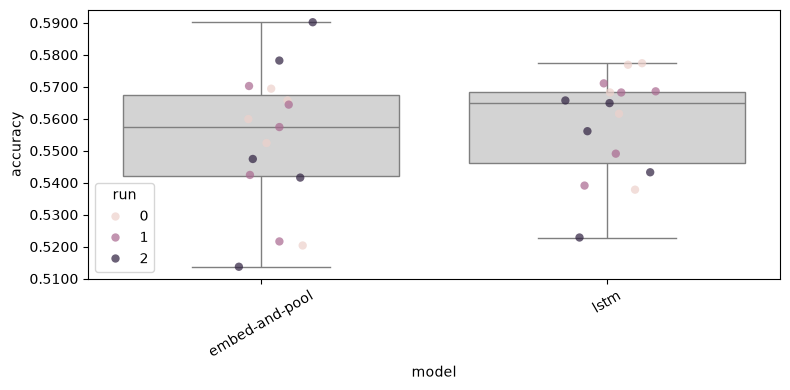

embed-and-pool  mean=0.5530  std=0.0213  (n=15)
lstm            mean=0.5581  std=0.0156  (n=15)


In [41]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

for name, runs in my_classifiers.items():
    accs = np.array([list(run['accuracies'].values()) for run in runs])   # shape [seeds, folds]
    print(f"{name:15s} mean={accs.mean():.4f}  std={accs.std():.4f}  (n={accs.size})")